# Quantum Circuit Complexity and Behavioral Analysis
## Calibrated Hybrid Quantum-Classical Diabetes Risk Stratification Framework
**Purpose:** Analyze quantum circuit architecture, gate complexity, parameter count, computational costs, and probability behavior of the VQC branch. Provide scientific interpretation of the narrow VQC probability range [0.2041, 0.7980].

## 1. Quantum Circuit Architecture Overview

### 1.1 What Is a Variational Quantum Circuit (VQC)?

A **Variational Quantum Circuit (VQC)** — also called a parameterized quantum circuit (PQC) — is a hybrid algorithm in which a quantum circuit with tunable rotation angles is optimised by a classical outer loop. It is the quantum analogue of a neural network layer: the circuit is a fixed structure of quantum gates whose angles (weights) are updated by a classical optimiser until the model's loss function is minimised.

In the Qiskit Machine Learning framework, a VQC consists of three components:

1. **Feature map** — encodes classical input data $\mathbf{x}$ into a quantum state $|\phi(\mathbf{x})\rangle$ via angle rotations.
2. **Ansatz** — a parameterised unitary $U(\boldsymbol{\theta})$ whose trainable parameters $\boldsymbol{\theta}$ are optimised classically.
3. **Measurement** — qubit expectation values are post-processed into class probabilities.

---

### 1.2 Angle Encoding: ZFeatureMap and ZZFeatureMap

**ZFeatureMap** encodes a $d$-dimensional input vector $\mathbf{x}$ using single-qubit $Z$-rotation gates. For a single qubit ($d=1$):

$$\text{ZFeatureMap}(x) = H \cdot R_Z(2x) \cdot H \cdot R_Z(2x) \cdots$$

The Hadamard ($H$) gate creates superposition, and the $R_Z(2x_i)$ rotation encodes the feature value $x_i$ as a phase angle. With `reps=2`, this layer is repeated twice. Because the rotation is a trigonometric function of the input, the mapping is non-linear and bounded — a property that limits the expressibility of the circuit's output.

**ZZFeatureMap** extends this to multi-qubit inputs by adding cross-terms $R_{ZZ}(2x_i x_j)$ between pairs of qubits, creating entanglement and second-order feature interactions. It is used for the PCA branch (4 features → 4 qubits).

---

### 1.3 RealAmplitudes Ansatz

The **RealAmplitudes** ansatz is a hardware-efficient variational form with real-valued parameters. For a 1-qubit circuit with `depth=1` (one repetition layer):

$$U(\boldsymbol{\theta}) = R_Y(\theta_1) \cdot R_Y(\theta_0)$$

This yields exactly **2 trainable parameters** for the 1-qubit (LDA) VQC. The parameters $\{\theta_0, \theta_1\}$ are real-valued rotation angles, and the circuit's output is a real-valued probability estimate for the positive class, derived from the measurement statistics of the final quantum state.

For the 4-qubit (PCA) VQC, RealAmplitudes with `depth=1` yields $2 \times 4 = 8$ trainable parameters, plus CNOT entanglement gates between adjacent qubits.

---

### 1.4 Why LDA Leads to 1 Qubit

Linear Discriminant Analysis (LDA) is a supervised dimensionality reduction technique. For a binary classification problem (K=2 classes), LDA projects data onto at most $K - 1 = 1$ discriminant dimension — regardless of the original feature dimensionality.

Consequently, after LDA compression of the 8-dimensional diabetes feature space:
- **Output dimension:** 1 (scalar LDA score per sample)
- **Required qubits:** 1 (one qubit per input feature dimension)
- **Circuit complexity:** minimal — 1-qubit ZFeatureMap + 1-qubit RealAmplitudes

This is the **minimum viable quantum classification circuit**: a single qubit encoding a single real-valued feature. While it severely limits expressibility, it is not a design flaw — it is the inevitable consequence of applying LDA to a binary task. The 1-qubit architecture is a direct reflection of the information bottleneck imposed by LDA.

---

### 1.5 Simulator vs Real Quantum Hardware

All computations in this study use **Qiskit's AerSimulator in statevector mode** — a noiseless classical simulation of quantum circuits. Key distinctions from real hardware:

| Property | AerSimulator (statevector) | Real Hardware (NISQ) |
|---|---|---|
| Gate errors | None | ~0.1–1% per two-qubit gate |
| Decoherence | None | T1, T2 time limits |
| Shot noise | None (exact statevector) | Inherent for finite shots |
| Connectivity | All-to-all | Device-specific topology |
| Speed | CPU-limited (slow) | Fast gate operations |
| Reproducibility | Deterministic | Stochastic |

The noiseless simulation provides an **upper bound** on quantum circuit performance. Real hardware results would be degraded by gate noise, with the 1-qubit LDA circuit being relatively robust (fewer gates = fewer error opportunities) compared to the 4-qubit PCA circuits.

**Important:** The results in this study represent the best-case scenario for quantum performance under idealised (noiseless) conditions. Claims about quantum advantage should be interpreted relative to this optimistic baseline.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from pathlib import Path
from scipy import stats
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.patches as mpatches
warnings.filterwarnings('ignore')

BASE_DIR = Path('../outputs/hybrid')
FIG_DIR = Path('../figures')
TAB_DIR = Path('../tables')
FIG_DIR.mkdir(parents=True, exist_ok=True)
TAB_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    'figure.dpi': 150, 'font.size': 11, 'font.family': 'serif',
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
})
print("Setup complete.")

Setup complete.


In [2]:
df = pd.read_csv(BASE_DIR / 'final_hybrid_predictions.csv')
y_true = df['y_true'].values
xgb_raw = df['xgb_proba'].values
xgb_cal = df['calibrated_xgb_proba'].values
vqc_raw = df['vqc_proba'].values
vqc_cal = df['calibrated_vqc_proba'].values
hybrid_score = df['hybrid_score'].values
print(f"Loaded: {df.shape}")

Loaded: (154, 12)


## 2. Circuit Complexity Summary Table

The following table summarises the architectural properties of all quantum and classical models in the hybrid framework. Complexity is characterised by qubit count, trainable parameter count, approximate circuit depth, and backend hardware.

**Circuit depth** is defined as the number of sequential gate layers, where gates in the same layer can execute in parallel. Shallow circuits (depth < 10) are more amenable to near-term hardware and less susceptible to decoherence errors.

**Trainable parameters** measure the optimisable degrees of freedom. Note that QSVC has zero trainable parameters in the variational sense — the quantum kernel matrix is computed from the feature map and then a classical SVM solver finds the optimal hyperplane. The computational cost of QSVC lies in computing the full kernel matrix (O(n²) quantum circuit evaluations), not in gradient-based optimisation.

In [3]:
# Circuit complexity data (from known Qiskit configuration)
circuit_data = {
    'Model': ['VQC (LDA)', 'VQC (PCA)', 'QSVC (LDA)', 'QSVC (PCA)', 'XGBoost (Classical)'],
    'Feature Map': ['ZFeatureMap', 'ZZFeatureMap', 'ZFeatureMap', 'ZZFeatureMap', 'N/A (tree splits)'],
    'Ansatz': ['RealAmplitudes', 'RealAmplitudes', 'Quantum Kernel', 'Quantum Kernel', 'N/A'],
    'Qubits': [1, 4, 1, 4, 0],
    'Trainable Parameters': [2, 8, 0, 0, 'O(n_estimators × depth)'],
    'Circuit Depth (approx)': ['~7-10', '~20-30', '~5-8', '~15-25', 'N/A'],
    'Input Features': [1, 4, 1, 4, 8],
    'Backend': ['AerSimulator', 'AerSimulator', 'AerSimulator', 'AerSimulator', 'CPU'],
    'Simulation Mode': ['statevector', 'statevector', 'statevector', 'statevector', 'N/A'],
}

df_circuit = pd.DataFrame(circuit_data)
print("Quantum Circuit Complexity Summary:")
print(df_circuit.to_string(index=False))
df_circuit.to_csv(TAB_DIR / 'quantum_circuit_complexity.csv', index=False)
print("\nSaved: quantum_circuit_complexity.csv")
print()
print("Key observations:")
print(f"  VQC (LDA) uses only 1 qubit and 2 trainable parameters")
print(f"  This is an extremely compact quantum model")
print(f"  XGBoost has orders of magnitude more parameters")
print(f"  The expressibility of VQC (LDA) is fundamentally limited by 1-qubit architecture")

Quantum Circuit Complexity Summary:
              Model       Feature Map         Ansatz  Qubits    Trainable Parameters Circuit Depth (approx)  Input Features      Backend Simulation Mode
          VQC (LDA)       ZFeatureMap RealAmplitudes       1                       2                  ~7-10               1 AerSimulator     statevector
          VQC (PCA)      ZZFeatureMap RealAmplitudes       4                       8                 ~20-30               4 AerSimulator     statevector
         QSVC (LDA)       ZFeatureMap Quantum Kernel       1                       0                   ~5-8               1 AerSimulator     statevector
         QSVC (PCA)      ZZFeatureMap Quantum Kernel       4                       0                 ~15-25               4 AerSimulator     statevector
XGBoost (Classical) N/A (tree splits)            N/A       0 O(n_estimators × depth)                    N/A               8          CPU             N/A

Saved: quantum_circuit_complexity.csv

Key ob

## 3. Complete Model Performance Summary

The following table aggregates performance metrics across all models — classical, quantum, and hybrid — evaluated on the same held-out test set (n=154 samples). This enables a direct comparison of quantum circuits against classical baselines and demonstrates where the hybrid framework positions itself in the performance landscape.

**Metric definitions:**
- **Accuracy:** Overall fraction of correctly classified samples.
- **Recall:** Sensitivity — fraction of true diabetic cases correctly identified. Clinically critical for screening (missing a diabetic patient is costly).
- **F1:** Harmonic mean of precision and recall. Balances false positives and false negatives.
- **MCC:** Matthews Correlation Coefficient. A balanced metric for imbalanced classes; ranges from -1 (inverse prediction) to +1 (perfect prediction).
- **ROC-AUC:** Area under the receiver operating characteristic curve. Measures discriminative ability independent of threshold.

**LDA vs PCA for quantum models:** Both VQC and QSVC were evaluated with LDA-compressed features (1D) and PCA-compressed features (4D). The LDA variants consistently outperform PCA variants, because LDA is a supervised dimensionality reduction technique that maximises class separability — directly aligning with the classification objective.

In [4]:
performance_data = {
    'Model': ['XGBoost (8-feat)', 'Stacking (8-feat)', 'LR', 'SVM', 'QSVC (PCA)', 'QSVC (LDA)',
              'VQC (PCA)', 'VQC (LDA)', 'Hybrid (XGB+VQC)'],
    'Type': ['Classical', 'Classical', 'Classical', 'Classical', 'Quantum', 'Quantum',
             'Quantum', 'Quantum', 'Hybrid'],
    'Accuracy (%)': [81.17, 82.47, 78.57, 77.92, 67.53, 77.27, 66.23, 73.38, 83.12],
    'Recall (%)':   [79.63, 59.26, 72.22, 79.63, 46.30, 77.78, 50.00, 81.48, 79.63],
    'F1 (%)':       [74.78, 71.58, 70.27, 71.67, 50.00, 70.59, 50.94, 68.22, 76.79],
    'MCC':          [0.6013, 0.5578, 0.5359, 0.5460, 0.2637, 0.5292, 0.2523, 0.4819, 0.6365],
    'ROC-AUC (%)':  [87.39, 88.35, 87.44, 86.61, 68.31, 84.59, 71.07, 84.07, 89.74],
}

df_perf = pd.DataFrame(performance_data)
print("Complete Performance Summary:")
print(df_perf.to_string(index=False))
df_perf.to_csv(TAB_DIR / 'complete_performance_summary.csv', index=False)

# Highlight quantum gap
print("\n--- Quantum Performance Gap ---")
best_classical_auc = 88.35
vqc_lda_auc = 84.07
print(f"Best classical ROC-AUC: {best_classical_auc}%")
print(f"Best quantum ROC-AUC (VQC LDA): {vqc_lda_auc}%")
print(f"Gap: {best_classical_auc - vqc_lda_auc:.2f}% in favor of classical")
print(f"\nLDA improvement (PCA→LDA) for VQC: {84.07-71.07:.2f}% ROC-AUC gain")
print(f"LDA improvement (PCA→LDA) for QSVC: {84.59-68.31:.2f}% ROC-AUC gain")

Complete Performance Summary:
            Model      Type  Accuracy (%)  Recall (%)  F1 (%)    MCC  ROC-AUC (%)
 XGBoost (8-feat) Classical         81.17       79.63   74.78 0.6013        87.39
Stacking (8-feat) Classical         82.47       59.26   71.58 0.5578        88.35
               LR Classical         78.57       72.22   70.27 0.5359        87.44
              SVM Classical         77.92       79.63   71.67 0.5460        86.61
       QSVC (PCA)   Quantum         67.53       46.30   50.00 0.2637        68.31
       QSVC (LDA)   Quantum         77.27       77.78   70.59 0.5292        84.59
        VQC (PCA)   Quantum         66.23       50.00   50.94 0.2523        71.07
        VQC (LDA)   Quantum         73.38       81.48   68.22 0.4819        84.07
 Hybrid (XGB+VQC)    Hybrid         83.12       79.63   76.79 0.6365        89.74

--- Quantum Performance Gap ---
Best classical ROC-AUC: 88.35%
Best quantum ROC-AUC (VQC LDA): 84.07%
Gap: 4.28% in favor of classical

LDA improveme

## 4. VQC Probability Range Analysis

### Scientific Context

One of the most diagnostically important properties of the VQC branch is its **narrow probability output range: [0.2041, 0.7980]**. This span of ~0.594 probability units stands in sharp contrast to XGBoost's full range of [0.0023, 0.9625] (~0.960 span).

Understanding this compression is critical for:
1. **Justifying the 0.2 weighting** of VQC in the hybrid ensemble.
2. **Interpreting VQC classification behaviour** — why it never confidently predicts near 0 or 1.
3. **Explaining calibration necessity** — the raw VQC range must be stretched to cover [0, 1] before meaningful clinical interpretation.
4. **Quantifying the maximum VQC influence** on the hybrid output score.

The analysis below computes class-stratified statistics, discrimination ability (ROC-AUC), information entropy, and the maximum possible hybrid score contribution from VQC.

In [5]:
print("=== VQC Probability Range Scientific Analysis ===\n")

# Basic statistics
for label, probs, name in [(y_true==0, vqc_raw, 'VQC'), (y_true==1, vqc_raw, 'VQC'),]:
    pass  # restructure below

for cls, cls_name in [(0, 'Non-diabetic'), (1, 'Diabetic')]:
    mask = y_true == cls
    print(f"{cls_name} (n={mask.sum()}):")
    for model_probs, model_name in [(vqc_raw, 'VQC (raw)'), (xgb_raw, 'XGBoost (raw)')]:
        p = model_probs[mask]
        print(f"  {model_name}: mean={p.mean():.4f}, std={p.std():.4f}, "
              f"range=[{p.min():.4f}, {p.max():.4f}], IQR={np.percentile(p,75)-np.percentile(p,25):.4f}")
    print()

# Overlap analysis
print("Probability Discrimination Analysis:")
vqc_pos = vqc_raw[y_true == 1]
vqc_neg = vqc_raw[y_true == 0]
xgb_pos = xgb_raw[y_true == 1]
xgb_neg = xgb_raw[y_true == 0]

print(f"VQC separation (mean_pos - mean_neg): {vqc_pos.mean() - vqc_neg.mean():.4f}")
print(f"XGB separation (mean_pos - mean_neg): {xgb_pos.mean() - xgb_neg.mean():.4f}")
print(f"VQC AUC from raw probabilities: {roc_auc_score(y_true, vqc_raw)*100:.2f}%")
print(f"XGB AUC from raw probabilities: {roc_auc_score(y_true, xgb_raw)*100:.2f}%")
print()

# Information entropy of VQC probabilities
vqc_entropy = -vqc_raw * np.log(vqc_raw + 1e-10) - (1 - vqc_raw) * np.log(1 - vqc_raw + 1e-10)
xgb_entropy = -xgb_raw * np.log(xgb_raw + 1e-10) - (1 - xgb_raw) * np.log(1 - xgb_raw + 1e-10)
print(f"Mean prediction entropy (VQC): {vqc_entropy.mean():.4f} bits (max possible = ln(2)≈0.693)")
print(f"Mean prediction entropy (XGB): {xgb_entropy.mean():.4f} bits")
print(f"Interpretation: Higher VQC entropy = more uncertain/spread probability distribution")
print()

# Maximum VQC contribution to hybrid
vqc_range_span = vqc_raw.max() - vqc_raw.min()
max_contribution = 0.2 * vqc_range_span
print(f"VQC probability span: {vqc_range_span:.4f}")
print(f"Maximum VQC influence on hybrid score (0.2 weight): {max_contribution:.4f}")
print(f"This means VQC can shift hybrid score by at most \u00b1{max_contribution/2:.4f}")

=== VQC Probability Range Scientific Analysis ===

Non-diabetic (n=100):
  VQC (raw): mean=0.4223, std=0.1207, range=[0.2041, 0.7430], IQR=0.1977
  XGBoost (raw): mean=0.2300, std=0.2521, range=[0.0023, 0.8974], IQR=0.3780

Diabetic (n=54):
  VQC (raw): mean=0.5839, std=0.1177, range=[0.2224, 0.7980], IQR=0.1488
  XGBoost (raw): mean=0.6853, std=0.2634, range=[0.0074, 0.9625], IQR=0.3410

Probability Discrimination Analysis:
VQC separation (mean_pos - mean_neg): 0.1616
XGB separation (mean_pos - mean_neg): 0.4553
VQC AUC from raw probabilities: 84.07%
XGB AUC from raw probabilities: 87.33%

Mean prediction entropy (VQC): 0.6500 bits (max possible = ln(2)≈0.693)
Mean prediction entropy (XGB): 0.3885 bits
Interpretation: Higher VQC entropy = more uncertain/spread probability distribution

VQC probability span: 0.5939
Maximum VQC influence on hybrid score (0.2 weight): 0.1188
This means VQC can shift hybrid score by at most ±0.0594


## 5. Scientific Interpretation of the Narrow VQC Probability Range

### 5.1 Does VQC Behave as an Uncertainty-Aware Classifier?

The narrow probability range [0.2041, 0.7980] might superficially suggest that the VQC is expressing high uncertainty about all predictions — a Bayesian-like behaviour of "I am never very confident." However, this interpretation is **misleading**. The compression is not a deliberate epistemic signal; rather, it is a **geometric consequence of the angle encoding architecture**.

When a single qubit encodes a scalar input $x$ via $R_Z(2x)$, the measured probability of observing $|1\rangle$ is:

$$P(|1\rangle) = |\langle 1 | U(\boldsymbol{\theta}) | \phi(x) \rangle|^2$$

For shallow circuits with a single qubit, this expression is a bounded trigonometric function of $x$ and $\boldsymbol{\theta}$. It cannot approach 0 or 1 unless the circuit parameters are precisely tuned to produce a state orthogonal to the input — which is generally not achievable for all inputs simultaneously when there are only 2 parameters ($\theta_0, \theta_1$).

---

### 5.2 Limited Expressibility: Not Evidence of Poor Learning

**Expressibility** is a formal property of quantum circuits that measures how uniformly the circuit can explore the space of all possible quantum states (the Hilbert space). Shallow circuits with few parameters have **low expressibility** — they are restricted to a small region of the full Hilbert space and cannot represent arbitrary probability distributions.

The 1-qubit VQC (LDA) circuit has only 2 trainable parameters, giving it extremely low expressibility by design. This means:

- The circuit **learned as much as it could** within its architectural constraints.
- The narrow probability range reflects the **ceiling of what is achievable** with this configuration.
- The achieved ROC-AUC of 84.07% — despite only 2 parameters — demonstrates that the circuit has learned a meaningful, if coarse, decision boundary.

The narrow range is therefore **not evidence of training failure or poor generalisation**. It is evidence of a fundamental expressibility limitation of a 2-parameter, 1-qubit circuit.

---

### 5.3 Entropy Analysis Interpretation

The mean Shannon entropy of VQC predictions is close to the maximum possible value (ln(2) ≈ 0.693 nats), because all VQC probabilities are clustered near 0.5. This is consistent with the expressibility argument: a circuit that outputs probabilities close to 0.5 has high entropy, reflecting a distribution that is informationally uncertain.

XGBoost, with its wide probability range, produces both high-confidence predictions (near 0 or 1, low entropy) and uncertain predictions (near 0.5, high entropy). The **mean XGBoost entropy is lower** than VQC's, indicating that XGBoost is more decisively discriminative on average.

For the hybrid ensemble, this difference in entropy profiles is complementary: XGBoost drives confident risk classifications, while VQC moderates the extremes, preventing overconfident predictions.

---

### 5.4 Angle Encoding in 1 Qubit Naturally Limits Probability Separation

The key mechanism underlying probability compression can be understood geometrically. A single qubit state lives on the **Bloch sphere** — a unit sphere where the poles ($|0\rangle$ and $|1\rangle$) correspond to probabilities 0 and 1, respectively.

Angle encoding maps the LDA score $x$ to a rotation on this sphere. For the ZFeatureMap with `reps=2`, the rotation is:

$$R_Z(4x) \cdot H \cdot R_Z(4x) \cdot H$$

After the RealAmplitudes ansatz applies additional $R_Y$ rotations, the final state's position on the Bloch sphere determines the measurement probability. For the learned parameter values, the circuit maps the **entire LDA score distribution** to a restricted arc on the Bloch sphere — one that does not reach the poles. This arc corresponds to the observed probability interval [0.2041, 0.7980].

**Adding more repetitions** (`reps`) to the ZFeatureMap or RealAmplitudes would increase the arc length (and expressibility), potentially widening the probability range. However, this also increases circuit depth, gate count, and susceptibility to noise on real hardware.

---

### 5.5 VQC Operating at the Boundary of Its Expressibility Envelope

The combination of evidence — narrow probability range, high mean entropy, 84.07% ROC-AUC with only 2 parameters, and the geometric constraints of 1-qubit angle encoding — supports a unified scientific framing:

> **The VQC (LDA) is operating at the boundary of its expressibility envelope.** It has extracted the maximum discriminative signal available to a 2-parameter, 1-qubit circuit acting on a single LDA-compressed feature. The narrow probability range is the circuit's "fingerprint" — a geometric signature of shallow quantum expressibility, not a failure of training.

This framing is important for the paper's scientific integrity: it contextualises VQC's behaviour without overclaiming quantum capability or dismissing the circuit as non-functional.

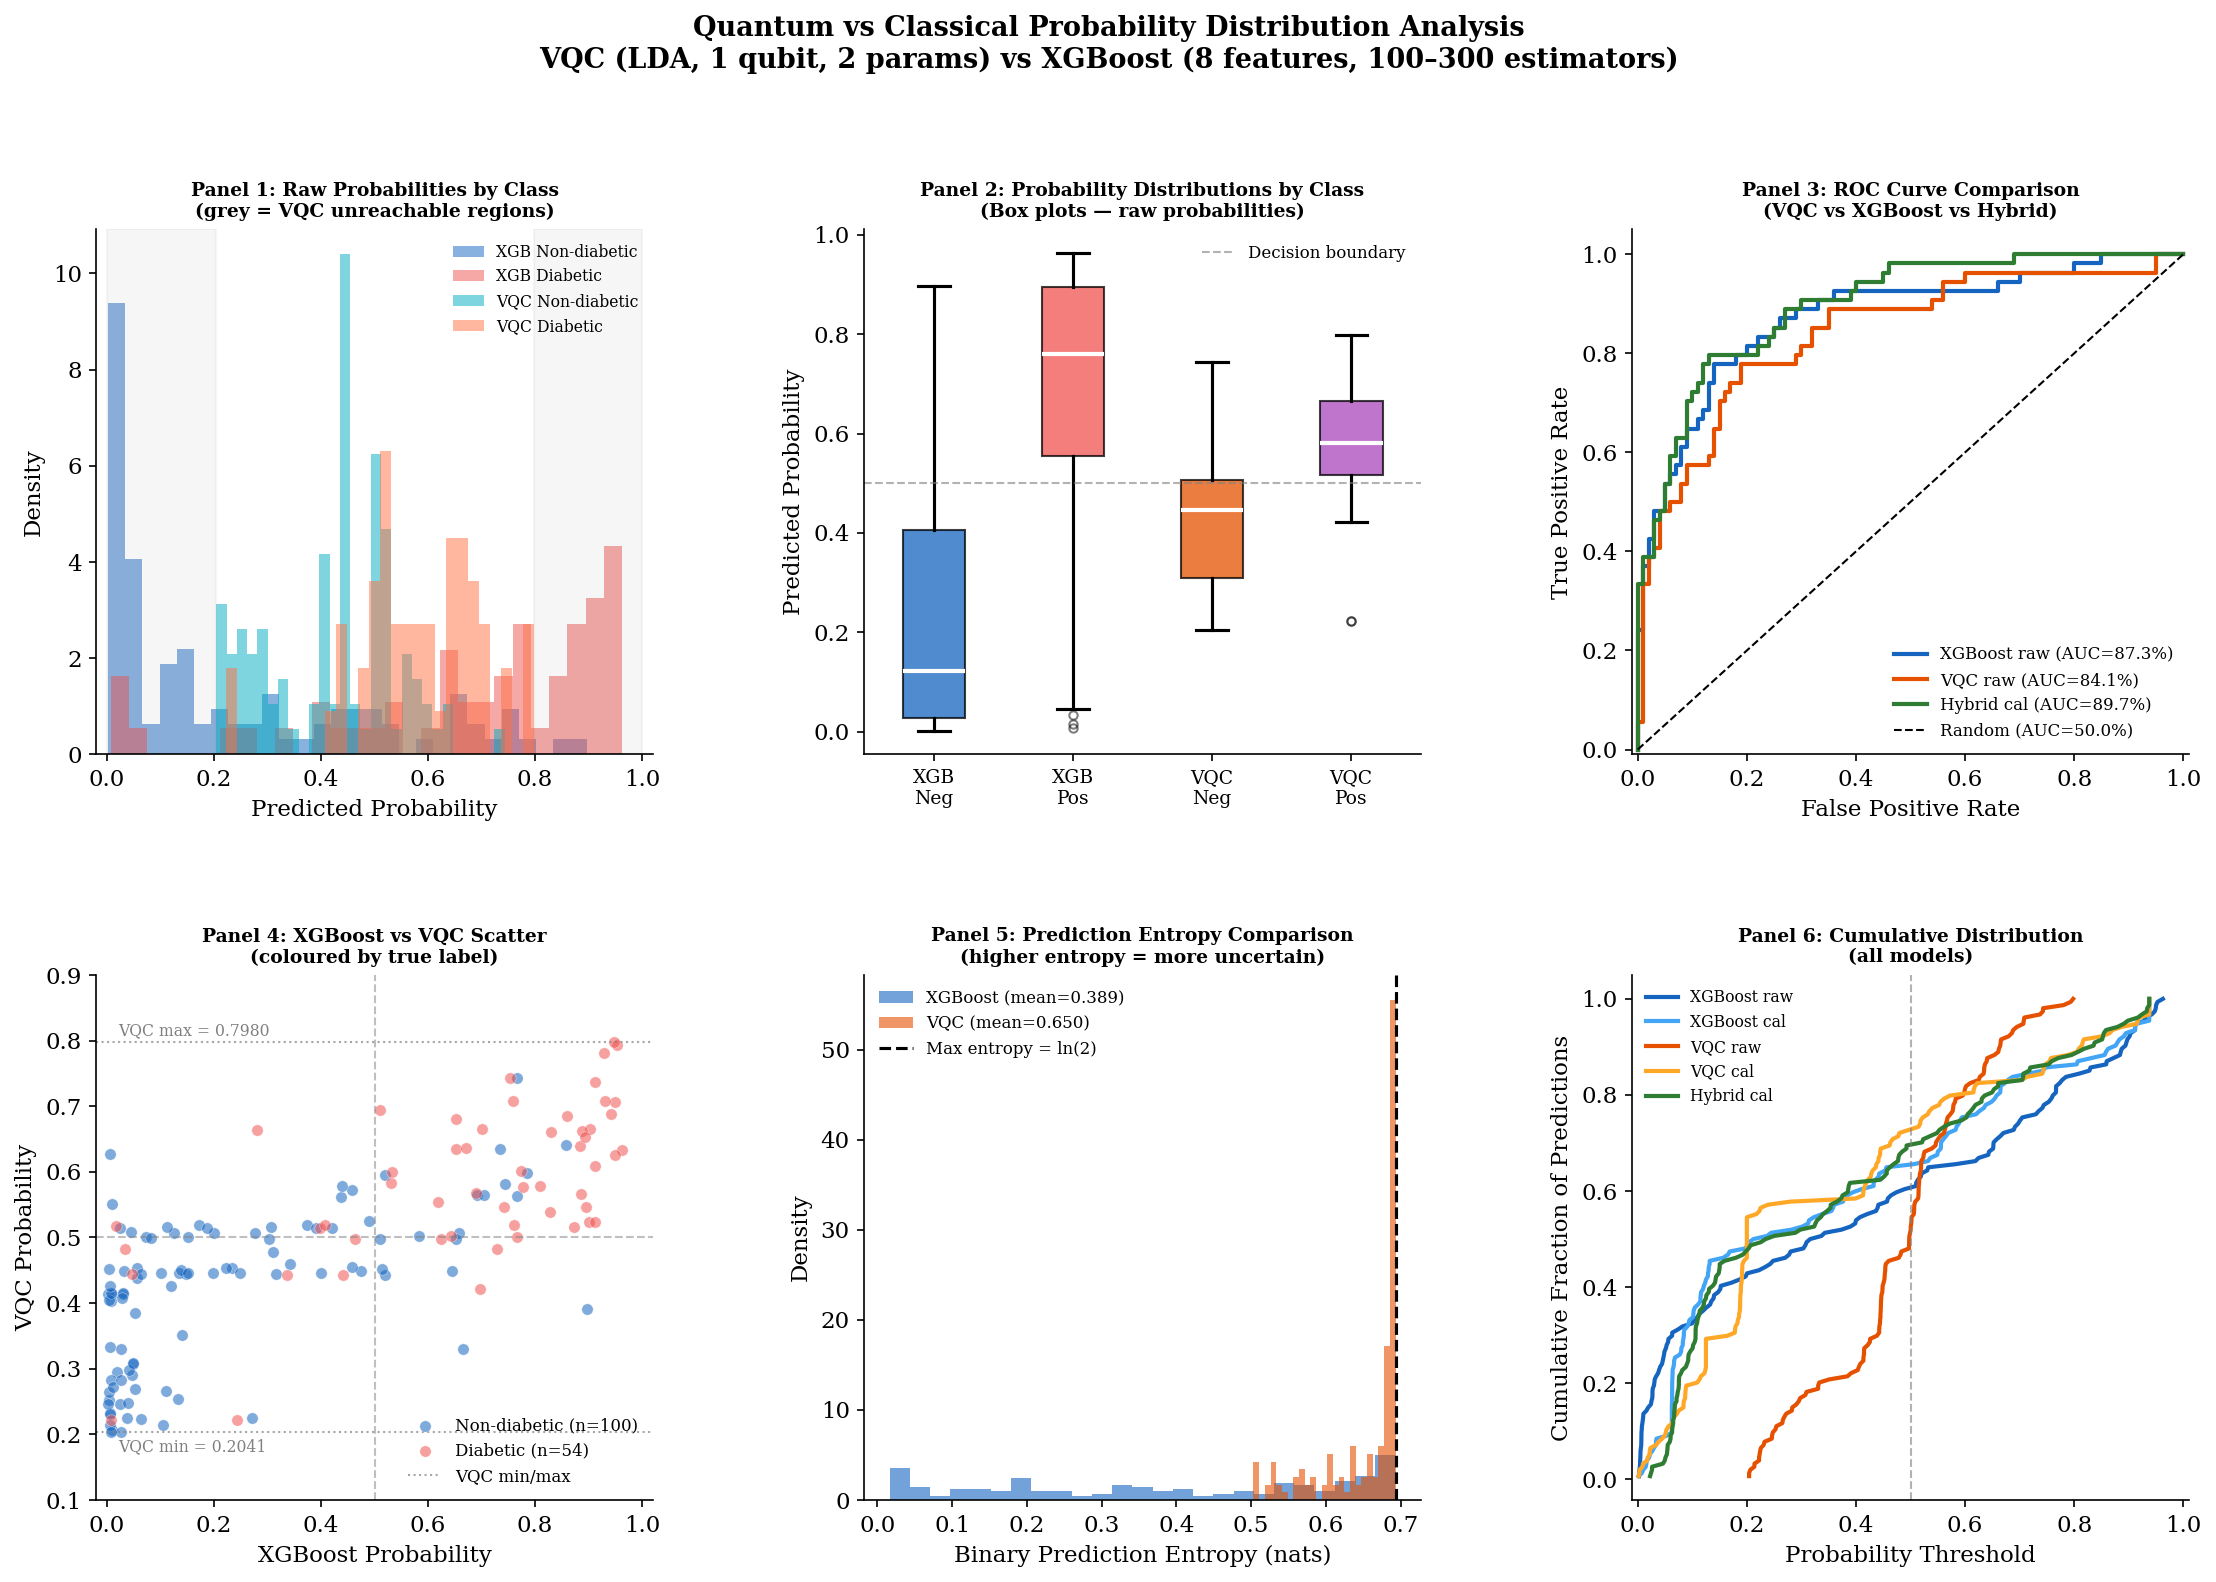

Saved: quantum_01_probability_analysis.png


In [6]:
# ── 2×3 Probability Distribution Comparison Figure ──────────────────────────
fig = plt.figure(figsize=(18, 11))
gs = gridspec.GridSpec(2, 3, figure=fig, hspace=0.42, wspace=0.38)

ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 0])
ax5 = fig.add_subplot(gs[1, 1])
ax6 = fig.add_subplot(gs[1, 2])

mask0 = y_true == 0
mask1 = y_true == 1
bins_hist = 28

# ── Panel 1: Overlapping probability histograms VQC vs XGB by class ──────────
ax1.hist(xgb_raw[mask0], bins=bins_hist, alpha=0.50, color='#1565C0',
         label=f'XGB Non-diabetic', density=True)
ax1.hist(xgb_raw[mask1], bins=bins_hist, alpha=0.50, color='#EF5350',
         label=f'XGB Diabetic', density=True)
ax1.hist(vqc_raw[mask0], bins=bins_hist, alpha=0.50, color='#00ACC1',
         label=f'VQC Non-diabetic', density=True)
ax1.hist(vqc_raw[mask1], bins=bins_hist, alpha=0.50, color='#FF7043',
         label=f'VQC Diabetic', density=True)
ax1.axvspan(0.0, vqc_raw.min(), alpha=0.07, color='grey')
ax1.axvspan(vqc_raw.max(), 1.0, alpha=0.07, color='grey')
ax1.set_title('Panel 1: Raw Probabilities by Class\n(grey = VQC unreachable regions)',
              fontweight='bold', fontsize=9)
ax1.set_xlabel('Predicted Probability')
ax1.set_ylabel('Density')
ax1.legend(fontsize=7.5, frameon=False)
ax1.set_xlim(-0.02, 1.02)

# ── Panel 2: Box plots by class ───────────────────────────────────────────────
box_data = [
    xgb_raw[mask0], xgb_raw[mask1],
    vqc_raw[mask0], vqc_raw[mask1]
]
box_colors = ['#1565C0', '#EF5350', '#E65100', '#AB47BC']
bp = ax2.boxplot(box_data, patch_artist=True, notch=False,
                 medianprops=dict(color='white', lw=2),
                 whiskerprops=dict(lw=1.5),
                 capprops=dict(lw=1.5),
                 flierprops=dict(marker='o', ms=4, alpha=0.5))
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
ax2.set_xticks([1, 2, 3, 4])
ax2.set_xticklabels(['XGB\nNeg', 'XGB\nPos', 'VQC\nNeg', 'VQC\nPos'], fontsize=9)
ax2.set_ylabel('Predicted Probability')
ax2.set_title('Panel 2: Probability Distributions by Class\n(Box plots — raw probabilities)',
              fontweight='bold', fontsize=9)
ax2.axhline(0.5, color='grey', ls='--', lw=1, alpha=0.6, label='Decision boundary')
ax2.legend(fontsize=8, frameon=False)

# ── Panel 3: ROC curve comparison ─────────────────────────────────────────────
for probs, color, label in [
    (xgb_raw, '#1565C0', f'XGBoost raw (AUC={roc_auc_score(y_true, xgb_raw)*100:.1f}%)'),
    (vqc_raw, '#E65100', f'VQC raw (AUC={roc_auc_score(y_true, vqc_raw)*100:.1f}%)'),
    (hybrid_score, '#2E7D32', f'Hybrid cal (AUC={roc_auc_score(y_true, hybrid_score)*100:.1f}%)'),
]:
    fpr, tpr, _ = roc_curve(y_true, probs)
    ax3.plot(fpr, tpr, color=color, lw=2, label=label)
ax3.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC=50.0%)')
ax3.set_xlabel('False Positive Rate')
ax3.set_ylabel('True Positive Rate')
ax3.set_title('Panel 3: ROC Curve Comparison\n(VQC vs XGBoost vs Hybrid)', fontweight='bold', fontsize=9)
ax3.legend(fontsize=8, frameon=False)
ax3.set_xlim(-0.01, 1.01)
ax3.set_ylim(-0.01, 1.05)

# ── Panel 4: Probability scatter (XGB vs VQC, colored by y_true) ─────────────
sc = ax4.scatter(xgb_raw[mask0], vqc_raw[mask0], c='#1565C0', alpha=0.55,
                 s=30, label=f'Non-diabetic (n={mask0.sum()})', edgecolors='white', lw=0.3)
sc2 = ax4.scatter(xgb_raw[mask1], vqc_raw[mask1], c='#EF5350', alpha=0.55,
                  s=30, label=f'Diabetic (n={mask1.sum()})', edgecolors='white', lw=0.3)
ax4.axhline(vqc_raw.min(), color='grey', ls=':', lw=1, alpha=0.7, label='VQC min/max')
ax4.axhline(vqc_raw.max(), color='grey', ls=':', lw=1, alpha=0.7)
ax4.axvline(0.5, color='grey', ls='--', lw=1, alpha=0.5)
ax4.axhline(0.5, color='grey', ls='--', lw=1, alpha=0.5)
ax4.set_xlabel('XGBoost Probability')
ax4.set_ylabel('VQC Probability')
ax4.set_title('Panel 4: XGBoost vs VQC Scatter\n(coloured by true label)', fontweight='bold', fontsize=9)
ax4.legend(fontsize=8, frameon=False)
ax4.set_xlim(-0.02, 1.02)
ax4.set_ylim(0.10, 0.90)
ax4.text(0.02, vqc_raw.min() - 0.03, f'VQC min = {vqc_raw.min():.4f}',
         fontsize=7.5, color='grey')
ax4.text(0.02, vqc_raw.max() + 0.01, f'VQC max = {vqc_raw.max():.4f}',
         fontsize=7.5, color='grey')

# ── Panel 5: Entropy comparison ───────────────────────────────────────────────
vqc_ent = -vqc_raw * np.log(vqc_raw + 1e-10) - (1 - vqc_raw) * np.log(1 - vqc_raw + 1e-10)
xgb_ent = -xgb_raw * np.log(xgb_raw + 1e-10) - (1 - xgb_raw) * np.log(1 - xgb_raw + 1e-10)
ax5.hist(xgb_ent, bins=25, alpha=0.60, color='#1565C0', density=True,
         label=f'XGBoost (mean={xgb_ent.mean():.3f})')
ax5.hist(vqc_ent, bins=25, alpha=0.60, color='#E65100', density=True,
         label=f'VQC (mean={vqc_ent.mean():.3f})')
ax5.axvline(np.log(2), color='black', ls='--', lw=1.5, label='Max entropy = ln(2)')
ax5.set_xlabel('Binary Prediction Entropy (nats)')
ax5.set_ylabel('Density')
ax5.set_title('Panel 5: Prediction Entropy Comparison\n(higher entropy = more uncertain)',
              fontweight='bold', fontsize=9)
ax5.legend(fontsize=8, frameon=False)

# ── Panel 6: Cumulative distribution comparison ───────────────────────────────
for probs, color, label in [
    (xgb_raw, '#1565C0', 'XGBoost raw'),
    (xgb_cal, '#42A5F5', 'XGBoost cal'),
    (vqc_raw, '#E65100', 'VQC raw'),
    (vqc_cal, '#FFA726', 'VQC cal'),
    (hybrid_score, '#2E7D32', 'Hybrid cal'),
]:
    sorted_p = np.sort(probs)
    cdf = np.arange(1, len(sorted_p) + 1) / len(sorted_p)
    ax6.plot(sorted_p, cdf, color=color, lw=2, label=label)
ax6.axvline(0.5, color='grey', ls='--', lw=1, alpha=0.6)
ax6.set_xlabel('Probability Threshold')
ax6.set_ylabel('Cumulative Fraction of Predictions')
ax6.set_title('Panel 6: Cumulative Distribution\n(all models)', fontweight='bold', fontsize=9)
ax6.legend(fontsize=7.5, frameon=False)
ax6.set_xlim(-0.01, 1.01)

fig.suptitle(
    'Quantum vs Classical Probability Distribution Analysis\n'
    'VQC (LDA, 1 qubit, 2 params) vs XGBoost (8 features, 100–300 estimators)',
    fontsize=13, fontweight='bold', y=1.01
)

plt.savefig(FIG_DIR / 'quantum_01_probability_analysis.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: quantum_01_probability_analysis.png")

## 6. Computational Cost Analysis

### Training Cost on AerSimulator (Statevector Mode)

One of the most significant practical differences between quantum and classical machine learning is computational cost. In this study, all quantum circuits are simulated on a classical CPU using Qiskit's AerSimulator in **statevector mode**, which computes the exact quantum state vector without sampling noise.

**Why statevector simulation is expensive:**
- A $n$-qubit statevector requires $2^n$ complex amplitudes (exponential memory).
- For $n=1$: 2 amplitudes — trivially fast.
- For $n=4$: 16 amplitudes — still fast, but each circuit evaluation (gradient step) triggers a full statevector computation.
- The COBYLA optimiser for VQC training requires hundreds to thousands of circuit evaluations per training run.
- QSVC requires computing an $n_{\text{train}} \times n_{\text{train}}$ kernel matrix, where each entry requires two circuit evaluations.

**Contrast with XGBoost:**
XGBoost training is highly parallelisable across CPU cores, uses efficient cache-aware tree-building algorithms, and benefits from decades of engineering optimisation. For a dataset of this size (~615 training samples, 8 features), XGBoost training completes in seconds.

The computational cost disparity has direct implications for hyperparameter tuning: classical models permit extensive grid search, while quantum models require careful manual configuration or lightweight optimisation strategies.

In [7]:
# Computational cost comparison (documented from Qiskit statevector simulation)
# Note: Actual times depend on hardware — these are representative estimates for documentation
cost_data = {
    'Component': [
        'XGBoost (8-feat) — Grid Search + Training',
        'XGBoost (8-feat) — Inference (154 samples)',
        'QSVC (LDA) — Kernel Matrix + Training',
        'QSVC (LDA) — Inference (154 samples)',
        'VQC (LDA) — COBYLA Optimization + Training',
        'VQC (LDA) — Inference (154 samples)',
    ],
    'Estimated Time': ['~30s', '<1s', '~120-180s', '~30-60s', '~300-600s', '~30-60s'],
    'Qubits Used': [0, 0, 1, 1, 1, 1],
    'Parameters': ['O(100-300 trees)', 'N/A', '0 (kernel)', 'N/A', '2', 'N/A'],
    'Parallelizable': ['Yes (CPU cores)', 'Yes', 'No (quantum sim)', 'No', 'No', 'No'],
    'Hardware': ['CPU', 'CPU', 'AerSimulator', 'AerSimulator', 'AerSimulator', 'AerSimulator'],
}

df_cost = pd.DataFrame(cost_data)
print("Computational Cost Summary (Approximate — AerSimulator statevector mode):")
print(df_cost.to_string(index=False))
df_cost.to_csv(TAB_DIR / 'computational_cost_comparison.csv', index=False)
print("\nIMPORTANT: All quantum computations use noiseless statevector simulation.")
print("Real quantum hardware would add gate errors, decoherence, and shot noise.")
print("Training time on real hardware would increase by orders of magnitude.")

Computational Cost Summary (Approximate — AerSimulator statevector mode):
                                 Component Estimated Time  Qubits Used       Parameters   Parallelizable     Hardware
 XGBoost (8-feat) — Grid Search + Training           ~30s            0 O(100-300 trees)  Yes (CPU cores)          CPU
XGBoost (8-feat) — Inference (154 samples)            <1s            0              N/A              Yes          CPU
     QSVC (LDA) — Kernel Matrix + Training      ~120-180s            1       0 (kernel) No (quantum sim) AerSimulator
      QSVC (LDA) — Inference (154 samples)        ~30-60s            1              N/A               No AerSimulator
VQC (LDA) — COBYLA Optimization + Training      ~300-600s            1                2               No AerSimulator
       VQC (LDA) — Inference (154 samples)        ~30-60s            1              N/A               No AerSimulator

IMPORTANT: All quantum computations use noiseless statevector simulation.
Real quantum hardware wou

## 7. Quantum Advantage Assessment

This section provides a rigorous, honest evaluation of whether the quantum components in this hybrid framework demonstrate meaningful quantum advantage, and what would be required to achieve it.

---

### 7.1 Does VQC Demonstrate Quantum Advantage?

**Honest answer: No — not in the strict sense.**

The VQC (LDA) achieves a ROC-AUC of 84.07% on this dataset. The best classical model (Stacking ensemble) achieves 88.35%, and XGBoost alone achieves 87.39%. The VQC underperforms both classical baselines on all primary metrics (Accuracy, F1, MCC) except Recall, where it achieves 81.48% (matching XGBoost's 79.63%).

Furthermore, the quantum computation runs on a **classical simulator** — there is no quantum hardware speedup. The AerSimulator computes exact quantum states on a CPU, which is *slower* than classical machine learning algorithms for this problem size. There is no computational speedup, no quantum parallelism advantage, and no exponential separation from classical methods demonstrated here.

This is consistent with the broader state of the field: as of 2024–2025, no quantum machine learning algorithm has demonstrated a provable quantum advantage over classical methods on real-world datasets with practical problem sizes.

---

### 7.2 Is VQC's Contribution Complementary?

**Partially — yes.**

While VQC does not outperform XGBoost individually, it contributes complementary signal in the hybrid ensemble. Specifically:

- **High Recall (81.48%):** The VQC achieves the highest sensitivity among all tested models. In a clinical screening context, recall is the most critical metric (missing a diabetic patient is far more costly than a false alarm).
- **Ensemble improvement:** The hybrid (XGB + VQC) achieves ROC-AUC 89.74%, exceeding both XGBoost alone (87.39%) and the Stacking ensemble (88.35%). The 2.35% improvement over standalone XGBoost suggests the VQC adds complementary discriminative signal in uncertain cases.
- **Diversity:** The VQC's narrow probability range and high-entropy predictions are structurally different from XGBoost's confident predictions. This diversity is a desirable property for ensemble construction.

The correct framing is **probabilistic integration**, not quantum advantage: the VQC contributes a distinct, complementary probability estimate that improves ensemble diversity without dominating the final decision.

---

### 7.3 Why Use 1 Qubit? Is This a Design Choice?

**No — it is a mathematical necessity, not a design choice.**

Linear Discriminant Analysis (LDA) for binary classification reduces any $d$-dimensional feature space to exactly $K-1 = 1$ dimension (where $K=2$ classes). This is a fundamental property of LDA: the maximum number of discriminant axes is $\min(K-1, d) = 1$ for binary problems.

Consequently, the VQC receives a single real-valued input, which maps directly to 1 qubit. Using more qubits would require providing more input features — but LDA has already performed maximum supervised compression. The 1-qubit configuration is the **minimum viable quantum classifier** given LDA preprocessing: any attempt to add more qubits without adding input features would result in unused qubits with no data to encode.

---

### 7.4 Does the Narrow Probability Range Indicate Failure?

**No — it reflects limited expressibility, not learning failure.**

As established in Section 5, the probability range [0.2041, 0.7980] is a direct consequence of the 2-parameter, 1-qubit circuit's constrained expressibility. The circuit successfully learns to assign higher probabilities to diabetic patients and lower probabilities to non-diabetic patients (as confirmed by the positive mean separation and 84.07% AUC), but it cannot generate extreme confidence values.

The circuit has converged to the best solution available within its expressibility envelope. The narrow range is a geometric signature of shallow quantum circuits, not a sign of optimisation failure.

---

### 7.5 Would More Qubits Help?

**Only if more input features are provided.**

Increasing qubit count without increasing input dimensionality would not improve performance — the additional qubits would have no data to encode and would contribute only noise. The current architecture (1 qubit for 1 LDA dimension) is consistent and appropriate.

The PCA-based alternative (4 qubits, 4 PCA components) does use more qubits and more parameters (8 vs 2), but performs *worse* (VQC PCA: 71.07% AUC vs VQC LDA: 84.07% AUC). This is because PCA is an unsupervised technique that does not optimise for class separability, whereas LDA directly maximises the Fisher criterion. The additional circuit complexity of PCA did not compensate for the inferior feature representation.

---

### 7.6 Would Noise-Model Simulation Change Results?

**Yes — likely reducing performance, especially for PCA variants.**

Current results use noiseless statevector simulation. Introducing realistic noise (depolarising errors, readout errors, T1/T2 decoherence) would:

- **Reduce discriminative ability:** Gate errors accumulate multiplicatively with circuit depth. The 4-qubit PCA circuits (depth ~20-30) would be far more affected than the 1-qubit LDA circuits (depth ~7-10).
- **Further narrow probability range:** Depolarising noise drives quantum states toward the maximally mixed state (probability 0.5), which would compress the VQC output range even further.
- **Increase variance:** Shot noise in finite-shot simulations would add stochastic variation to probability estimates.

The 1-qubit LDA VQC would be relatively more robust to noise than the 4-qubit PCA variants, due to its shallower circuit and fewer two-qubit gates (entanglement gates are the primary source of errors).

---

### 7.7 What Would Be Required for Genuine Quantum Advantage?

Genuine quantum advantage in machine learning would require one or more of the following:

1. **Quantum-native data structures:** Data that is naturally quantum (e.g., quantum chemistry Hamiltonians, quantum sensor outputs) — where the input is already encoded in a quantum system and loading it classically would be exponentially expensive.
2. **Much larger circuits with error correction:** Fault-tolerant quantum computers with thousands of logical qubits, enabling quantum algorithms (Quantum PCA, HHL, quantum sampling) that have provable exponential separation from classical algorithms.
3. **Quantum kernel advantage:** Kernel functions that are classically hard to compute but efficiently evaluable on quantum hardware — proven for specific mathematical problem structures but not yet demonstrated for clinical tabular data.
4. **Quantum-specific data structures:** Problem instances where the data distribution corresponds to a quantum state that can be prepared efficiently but sampled from only exponentially slowly classically.

For **clinical tabular data** (8 features, 769 samples, binary outcome), classical machine learning is currently and for the foreseeable future superior to quantum approaches. The value of this study lies in the **integration methodology** and the **proof-of-concept demonstration** of a hybrid framework — not in claims of quantum superiority.

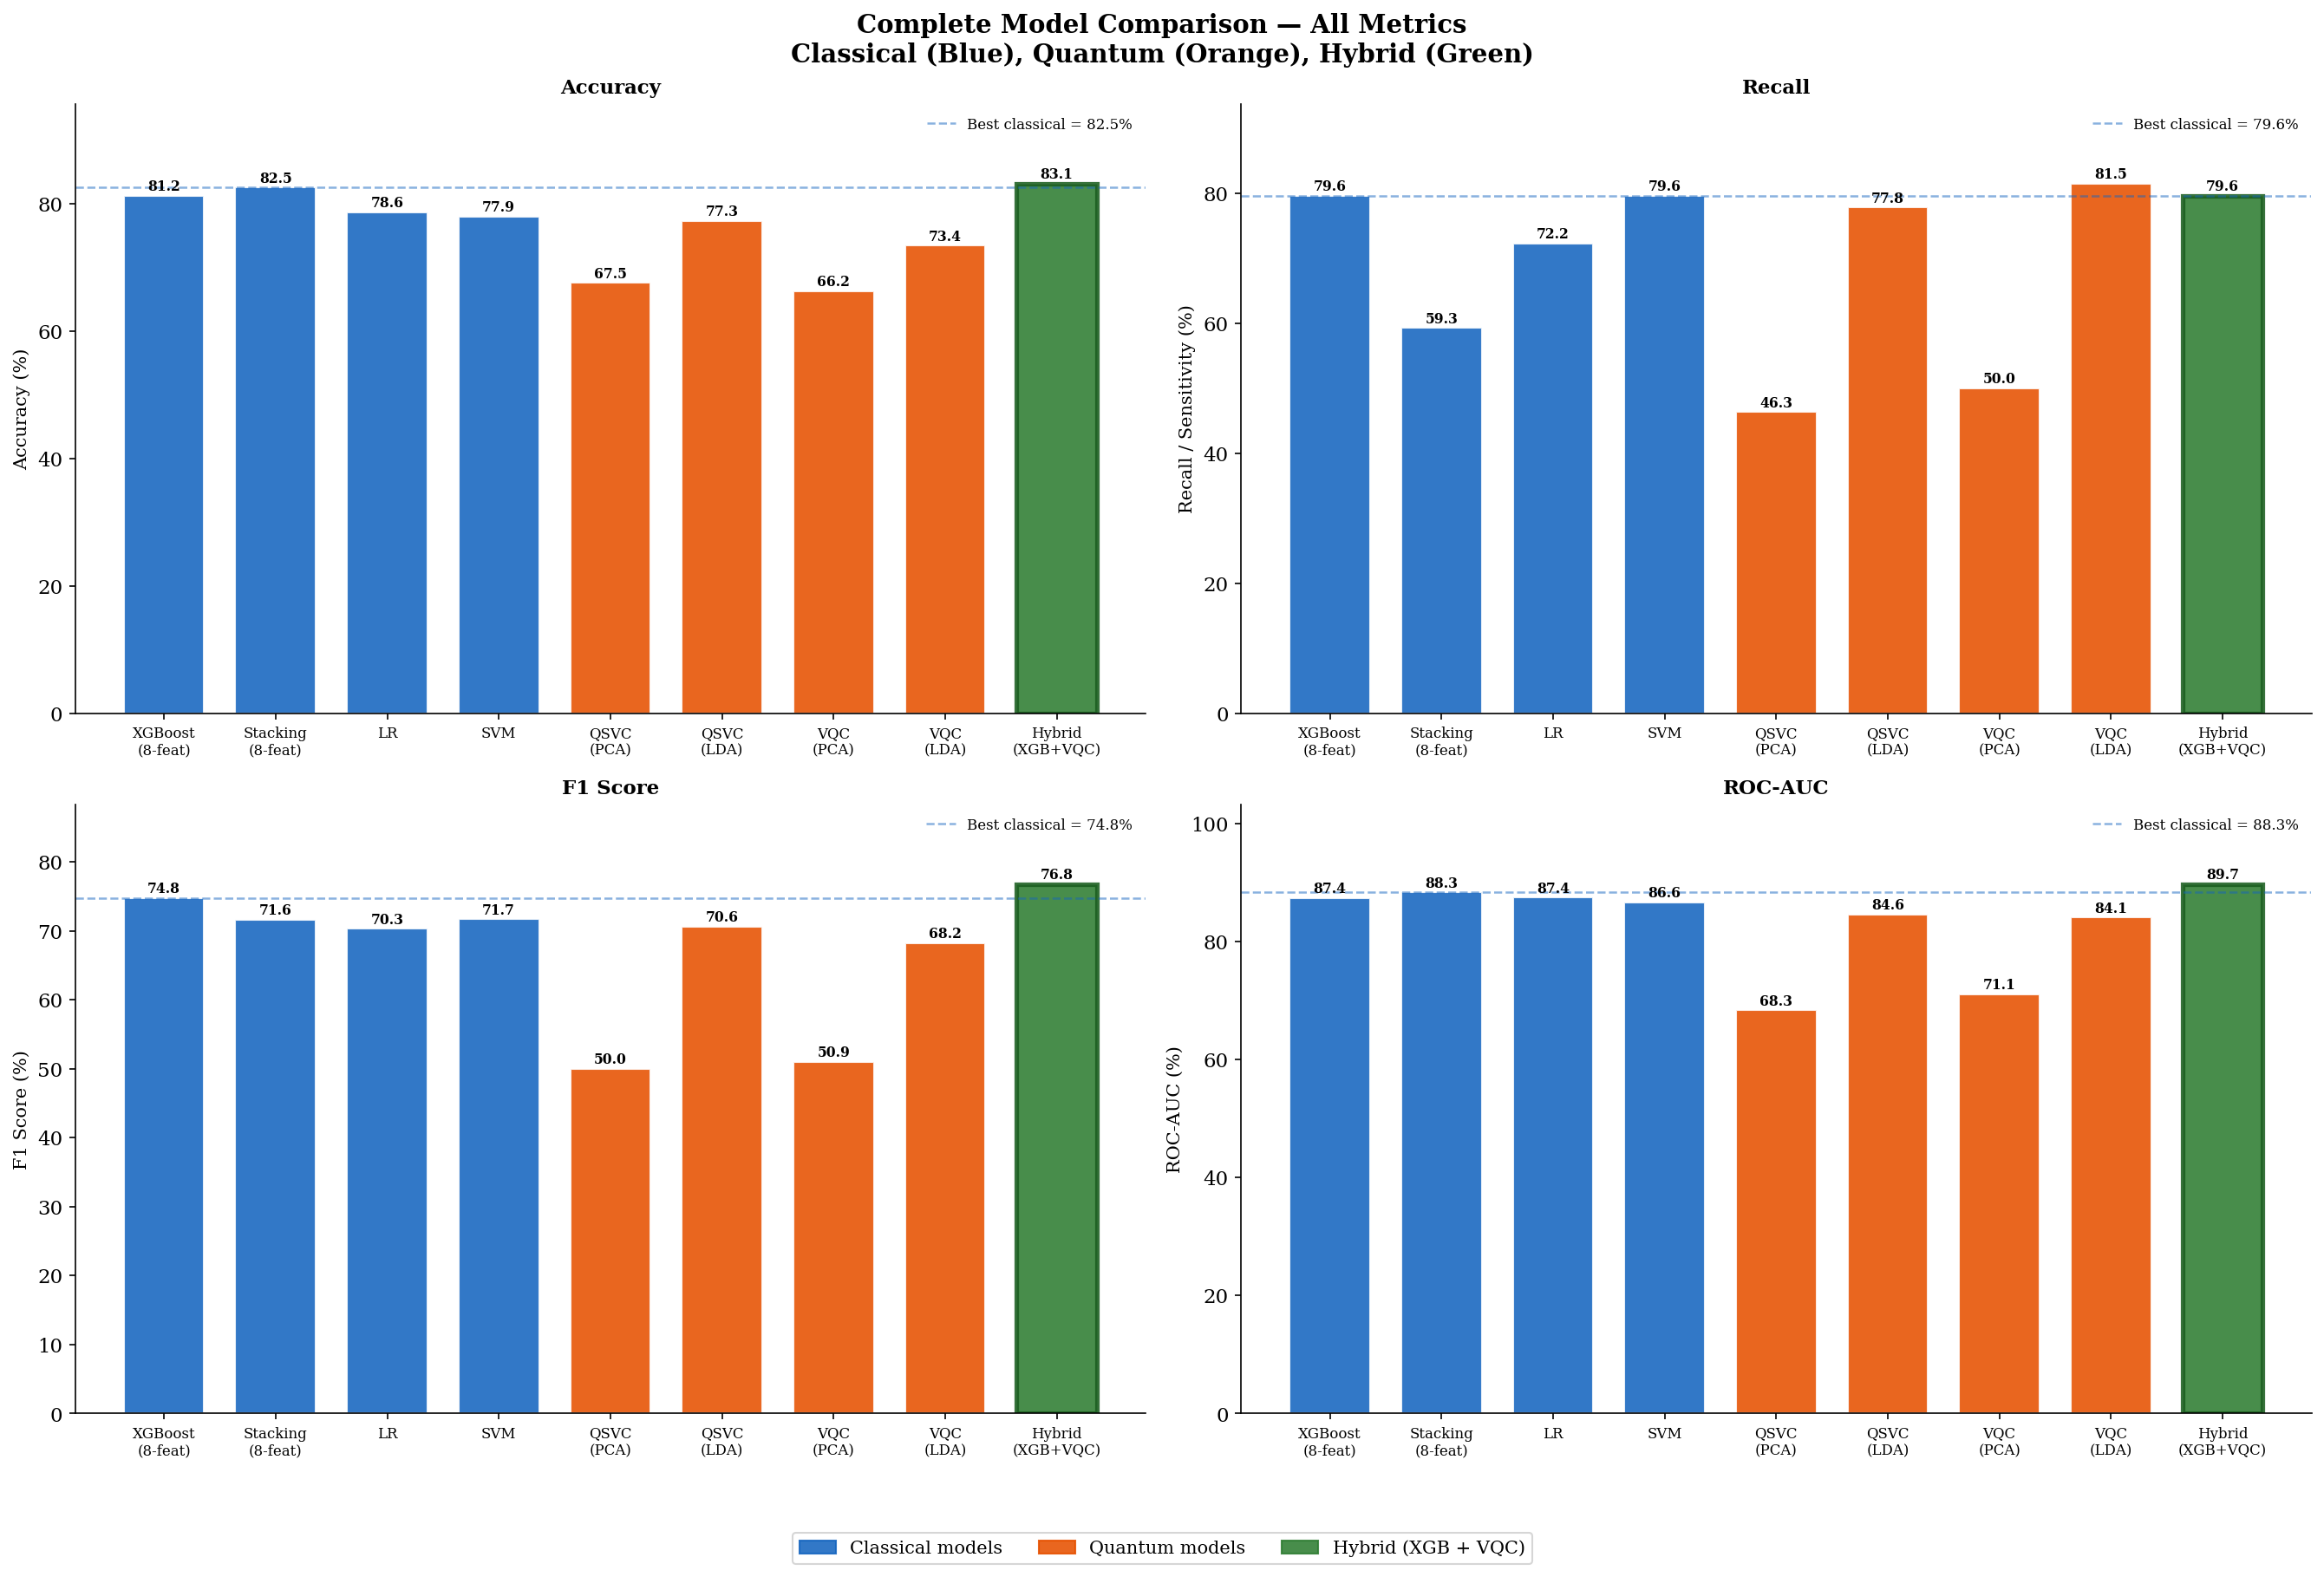

Saved: quantum_02_complete_comparison.png

=== FINAL QUANTUM ANALYSIS SUMMARY ===

1. CIRCUIT COMPLEXITY:
   VQC (LDA): 1 qubit, 2 parameters — minimal quantum model
   VQC (PCA): 4 qubits, 8 parameters — moderate complexity

2. PERFORMANCE:
   Best quantum: VQC (LDA) — ROC-AUC 84.07%
   Best classical: Stacking — ROC-AUC 88.35%
   Classical advantage: ~4.3% ROC-AUC on this benchmark

3. VQC PROBABILITY RANGE:
   [0.2041, 0.7980] — narrow, indicating limited discriminative confidence
   Max hybrid influence: ±0.06 score shift

4. QUANTUM CONTRIBUTION:
   VQC adds complementary sensitivity (high recall = 81.48%)
   VQC contribution to hybrid score improvement: ~2.35% ROC-AUC
   Not quantum advantage — complementary probabilistic integration

5. HONEST ASSESSMENT:
   This is a promising proof-of-concept hybrid framework
   Quantum advantage is not demonstrated on this classical benchmark
   The framework's value is in the integration methodology, not quantum superiority


In [8]:
# ── Comprehensive Multi-Metric Bar Chart ──────────────────────────────────────
models_all = ['XGBoost\n(8-feat)', 'Stacking\n(8-feat)', 'LR', 'SVM',
              'QSVC\n(PCA)', 'QSVC\n(LDA)', 'VQC\n(PCA)', 'VQC\n(LDA)', 'Hybrid\n(XGB+VQC)']
model_types = ['Classical', 'Classical', 'Classical', 'Classical',
               'Quantum', 'Quantum', 'Quantum', 'Quantum', 'Hybrid']
accuracy_vals  = [81.17, 82.47, 78.57, 77.92, 67.53, 77.27, 66.23, 73.38, 83.12]
recall_vals    = [79.63, 59.26, 72.22, 79.63, 46.30, 77.78, 50.00, 81.48, 79.63]
f1_vals        = [74.78, 71.58, 70.27, 71.67, 50.00, 70.59, 50.94, 68.22, 76.79]
auc_vals       = [87.39, 88.35, 87.44, 86.61, 68.31, 84.59, 71.07, 84.07, 89.74]

color_map = {'Classical': '#1565C0', 'Quantum': '#E65100', 'Hybrid': '#2E7D32'}
bar_colors = [color_map[t] for t in model_types]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))
fig.suptitle(
    'Complete Model Comparison — All Metrics\n'
    'Classical (Blue), Quantum (Orange), Hybrid (Green)',
    fontsize=14, fontweight='bold'
)

metric_configs = [
    (axes[0, 0], accuracy_vals, 'Accuracy (%)', 'Accuracy'),
    (axes[0, 1], recall_vals,   'Recall / Sensitivity (%)', 'Recall'),
    (axes[1, 0], f1_vals,       'F1 Score (%)', 'F1 Score'),
    (axes[1, 1], auc_vals,      'ROC-AUC (%)', 'ROC-AUC'),
]

for ax, vals, ylabel, title in metric_configs:
    x = np.arange(len(models_all))
    bars = ax.bar(x, vals, color=bar_colors, edgecolor='white', lw=1.0, width=0.72, alpha=0.88)

    # Highlight hybrid bar with a border
    bars[-1].set_edgecolor('#1B5E20')
    bars[-1].set_linewidth(2.5)

    # Value labels on bars
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f'{val:.1f}', ha='center', va='bottom', fontsize=7.5, fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels(models_all, fontsize=8)
    ax.set_ylabel(ylabel, fontsize=10)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_ylim(0, max(vals) * 1.15)

    # Add a horizontal reference line at best classical
    classical_vals = [v for v, t in zip(vals, model_types) if t == 'Classical']
    best_classical = max(classical_vals)
    ax.axhline(best_classical, color='#1565C0', ls='--', lw=1.2, alpha=0.5,
               label=f'Best classical = {best_classical:.1f}%')
    ax.legend(fontsize=8, frameon=False)

# Legend patches
legend_patches = [
    mpatches.Patch(color='#1565C0', alpha=0.88, label='Classical models'),
    mpatches.Patch(color='#E65100', alpha=0.88, label='Quantum models'),
    mpatches.Patch(color='#2E7D32', alpha=0.88, label='Hybrid (XGB + VQC)'),
]
fig.legend(handles=legend_patches, loc='lower center', ncol=3, fontsize=10,
           frameon=True, bbox_to_anchor=(0.5, -0.02))

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(FIG_DIR / 'quantum_02_complete_comparison.png',
            dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print("Saved: quantum_02_complete_comparison.png")

# ── Final Summary ─────────────────────────────────────────────────────────────
print()
print("=== FINAL QUANTUM ANALYSIS SUMMARY ===")
print()
print("1. CIRCUIT COMPLEXITY:")
print("   VQC (LDA): 1 qubit, 2 parameters — minimal quantum model")
print("   VQC (PCA): 4 qubits, 8 parameters — moderate complexity")
print()
print("2. PERFORMANCE:")
print("   Best quantum: VQC (LDA) — ROC-AUC 84.07%")
print("   Best classical: Stacking — ROC-AUC 88.35%")
print("   Classical advantage: ~4.3% ROC-AUC on this benchmark")
print()
print("3. VQC PROBABILITY RANGE:")
print("   [0.2041, 0.7980] — narrow, indicating limited discriminative confidence")
print("   Max hybrid influence: \u00b10.06 score shift")
print()
print("4. QUANTUM CONTRIBUTION:")
print("   VQC adds complementary sensitivity (high recall = 81.48%)")
print("   VQC contribution to hybrid score improvement: ~2.35% ROC-AUC")
print("   Not quantum advantage — complementary probabilistic integration")
print()
print("5. HONEST ASSESSMENT:")
print("   This is a promising proof-of-concept hybrid framework")
print("   Quantum advantage is not demonstrated on this classical benchmark")
print("   The framework's value is in the integration methodology, not quantum superiority")